# Предсказание предпочтений TF-IDF и логистическая регрессия
ДЗ1, Андрей Заводов.

Гипотеза такая. модель по тексту запроса и двух ответов улучшит log loss относитльно частот классов в train.

In [ ]:

pip install numpy==2.2.6 pandas==2.3.3 scipy==1.15.3 scikit-learn==1.7.2 matplotlib==3.10.7 threadpoolctl==3.8.0 mlflow==3.7.0 sqlalchemy==2.0.44


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/3.3 MB ? eta -:--:--


   ━━━━━━━━━╸━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.8/3.3 MB 9.1 MB/s eta 0:00:01


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 18.9 MB/s  0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/624.4 kB ? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 624.4/624.4 kB 37.9 MB/s  0:00:00



  Attempting uninstall: sqlalchemy

    Found existing installation: SQLAlchemy 2.1.8

    Uninstalling SQLAlchemy-2.1.8:

      Successfully uninstalled SQLAlchemy-2.1.8



   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [sqlalchemy]


   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [sqlalchemy]


   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [sqlalchemy]


   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [sqlalchemy]


   ━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━━━━ 1/2 [sqlalchemy]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sqlalchemy]



In [2]:
import hashlib
import json
import unicodedata
import warnings
from pathlib import Path


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import log_loss, accuracy_score, f1_score, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits


In [4]:
params = {
    'seed': 42,
    'n_splits': 5,
    'max_features': 20000,
    'ngram_range': [1, 2],
    'min_df': 3,
    'sublinear_tf': True,
    'C': 1.0,
    'solver': 'lbfgs',
    'max_iter': 500,
    'tol': 0.0001,
    'bootstrap_samples': 1000,
}


In [5]:
data = pd.read_csv("train.csv", keep_default_na=False, dtype={"id": str})
assert len(data) > 0 and data.id.is_unique and data.id.ne("").all()
print("Строк:", len(data))


Строк: 57477


In [6]:
text_columns = ["prompt", "response_a", "response_b"]
classes = ["A", "B", "tie"]
labels = data[["winner_model_a", "winner_model_b", "winner_tie"]]
assert labels.isin([0, 1]).all().all() and labels.sum(axis=1).eq(1).all()
y = labels.to_numpy().argmax(axis=1)


In [7]:
def read_turns(value):
    turns = json.loads(value)
    assert isinstance(turns, list) and len(turns) > 0
    assert all(turn is None or isinstance(turn, str) for turn in turns)
    return [turn or "" for turn in turns]

turns = data[text_columns].map(read_turns)


In [8]:
turn_counts = turns.map(len)
assert turn_counts.nunique(axis=1).eq(1).all()
texts = turns.map("\n".join)
lengths = texts.map(len)


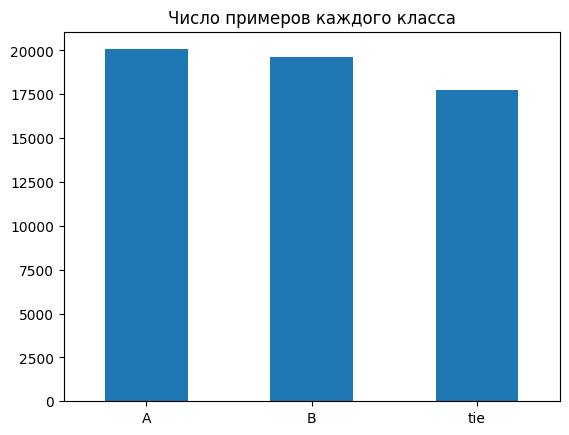

,prompt,response_a,response_b
count,57477.000000,57477.000000,57477.000000
mean,352.356612,1330.371488,1337.176714
std,1025.378233,1461.908578,1483.787471
min,3.000000,0.000000,0.000000
50%,91.000000,1036.000000,1044.000000
90%,758.000000,2703.000000,2695.000000
99%,4698.600000,6783.720000,6736.240000
max,32833.000000,53299.000000,52402.000000


In [9]:
class_counts = pd.Series(y).value_counts().sort_index()
class_counts.index = classes
class_counts.plot.bar(title="Число примеров каждого класса", rot=0)
plt.show()
lengths.describe(percentiles=[.5, .9, .99])


In [10]:
has_code = texts.apply(lambda column: column.str.contains("```", regex=False)).any(axis=1)
same_answers = texts.response_a.eq(texts.response_b)
pd.Series({
    "multi_turn": turn_counts.prompt.gt(1).sum(),
    "with_code": has_code.sum(),
    "same_answers": same_answers.sum(),
    "same_answers_not_tie": (same_answers & (y != 2)).sum(),
})


multi_turn              7539
with_code               6848
same_answers             275
same_answers_not_tie      27
dtype: int64

Одинаковые первые запросы оставляем в одной части, чтобы избежать утечки. Берем первый fold.


In [11]:
def prompt_group(first_turn):
    text = unicodedata.normalize("NFKC", first_turn).casefold()
    text = " ".join(text.split())
    return hashlib.sha256(text.encode()).hexdigest()

groups = turns.prompt.map(lambda conversation: prompt_group(conversation[0]))


In [12]:
seed = params["seed"]
splitter = StratifiedGroupKFold(n_splits=params["n_splits"], shuffle=True, random_state=seed)
train_idx, valid_idx = next(splitter.split(texts, y, groups))
assert not set(groups.iloc[train_idx]) & set(groups.iloc[valid_idx])
assert set(y[train_idx]) == set(y[valid_idx]) == {0, 1, 2}
print("Train:", len(train_idx), "Validation:", len(valid_idx))


Train: 45861 Validation: 11616


Словарь TF-IDF учим только на train. Запрос и ответы A/B кодируем отдельно.


In [13]:
train_texts = texts.iloc[train_idx]
valid_texts = texts.iloc[valid_idx]
vectorizer = TfidfVectorizer(
    max_features=params["max_features"],
    ngram_range=tuple(params["ngram_range"]), min_df=params["min_df"],
    sublinear_tf=params["sublinear_tf"], dtype=np.float32,
)
vectorizer.fit(pd.concat([train_texts[column] for column in text_columns]))


,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None
,analyzer,'word'
,stop_words,None
,token_pattern,'(?u)\\b\\w\\w+\\b'
,ngram_range,"(1, ...)"


In [14]:
train_blocks = []
valid_blocks = []
for column in text_columns:
    train_blocks.append(vectorizer.transform(train_texts[column]))
    valid_blocks.append(vectorizer.transform(valid_texts[column]))
X_train = sparse.hstack(train_blocks, format="csr")
X_valid = sparse.hstack(valid_blocks, format="csr")


In [15]:
y_train = y[train_idx]
y_valid = y[valid_idx]
print(X_train.shape, X_valid.shape)


(45861, 60000) (11616, 60000)


In [16]:
model = LogisticRegression(
    C=params["C"], solver=params["solver"],
    max_iter=params["max_iter"], tol=params["tol"],
)
with threadpool_limits(limits=4), warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    model.fit(X_train, y_train)
assert model.classes_.tolist() == [0, 1, 2]
print("Итераций:", model.n_iter_[0])


Итераций: 181


In [17]:
with threadpool_limits(limits=4):
    probabilities = model.predict_proba(X_valid)
    train_probabilities = model.predict_proba(X_train)


In [18]:
prior = np.bincount(y_train, minlength=3) / len(y_train)
prior_probabilities = np.tile(prior, (len(y_valid), 1))
uniform_probabilities = np.full((len(y_valid), 3), 1 / 3)


In [19]:
def metrics(target, proba):
    predicted = proba.argmax(axis=1)
    return {
        "log_loss": log_loss(target, proba, labels=[0, 1, 2]),
        "accuracy": accuracy_score(target, predicted),
        "macro_f1": f1_score(target, predicted, average="macro"),
    }


In [20]:
results = pd.DataFrame({
    "uniform": metrics(y_valid, uniform_probabilities),
    "prior": metrics(y_valid, prior_probabilities),
    "TF-IDF + LR": metrics(y_valid, probabilities),
    "LR on train": metrics(y_train, train_probabilities),
}).T
results


,log_loss,accuracy,macro_f1
uniform,1.098612,0.351928,0.173544
prior,1.097260,0.351928,0.173544
TF-IDF + LR,1.130115,0.430613,0.427005
LR on train,0.593667,0.866379,0.865834


Bootstrap по группам запросов.


In [21]:
losses = -np.log(np.clip(probabilities[np.arange(len(y_valid)), y_valid], np.finfo(float).eps, 1))
prior_losses = -np.log(prior[y_valid])


In [22]:
group_losses = pd.DataFrame({
    "group": groups.iloc[valid_idx].to_numpy(),
    "loss": losses,
    "delta": losses - prior_losses,
    "rows": 1,
}).groupby("group").sum().to_numpy()


In [23]:
rng = np.random.default_rng(seed)
bootstrap = []
for _ in range(params["bootstrap_samples"]):
    indexes = rng.integers(len(group_losses), size=len(group_losses))
    total = group_losses[indexes].sum(axis=0)
    bootstrap.append(total[:2] / total[2])


In [24]:
intervals = pd.DataFrame(
    np.quantile(bootstrap, [.025, .975], axis=0),
    index=["2.5%", "97.5%"], columns=["log_loss", "delta_vs_prior"],
)
print("Разница:", (losses - prior_losses).mean())
intervals


Разница: 0.03285459817375395


,log_loss,delta_vs_prior
2.5%,1.118621,0.021479
97.5%,1.142949,0.045497


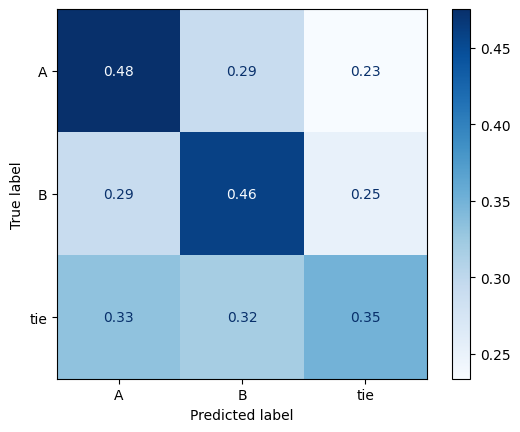

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_valid, probabilities.argmax(axis=1),
    display_labels=classes, normalize="true", cmap="Blues",
)
plt.show()


In [26]:
validation = pd.DataFrame({
    "id": data.id.iloc[valid_idx].to_numpy(),
    "target": y_valid,
    "predicted": probabilities.argmax(axis=1),
    "loss": losses,
    "with_code": has_code.iloc[valid_idx].to_numpy(),
    "multi_turn": turn_counts.prompt.iloc[valid_idx].gt(1).to_numpy(),
})
validation.groupby("with_code").loss.agg(["count", "mean"])


,count,mean
with_code,,
False,10159,1.121189
True,1457,1.192348


In [27]:
validation.groupby("multi_turn").loss.agg(["count", "mean"])


,count,mean
multi_turn,,
False,10103,1.129461
True,1513,1.134478


In [28]:
mistakes = validation[validation.target != validation.predicted]
mistakes.sort_values("loss", ascending=False).head(10)


,id,target,predicted,loss,with_code,multi_turn
6039,2217249332,0,2,5.261186,False,False
7120,2598065831,1,0,5.223096,False,False
1459,520948451,0,2,4.712163,False,False
7596,2794184157,1,0,4.627146,False,True
5103,1872385595,1,0,4.281300,False,False
10702,3942483861,0,1,4.173169,False,False
6814,2502431164,0,1,4.104153,True,False
10710,3943195465,0,1,4.072864,False,False
3815,1411597873,0,2,4.051372,False,True
7742,2847156518,0,1,3.954014,False,False


In [29]:
from datetime import datetime
output = Path("artifacts") / datetime.now().strftime("notebook-%Y%m%d-%H%M%S-%f")
output.mkdir(parents=True, exist_ok=False)
results.to_csv(output / "metrics.csv")
intervals.to_csv(output / "bootstrap.csv")
validation.to_csv(output / "validation.csv", index=False)
print(output)


artifacts/notebook-20261109-235723-731883


In [30]:
import mlflow

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("preferences-baseline")
with mlflow.start_run() as run:
    mlflow.log_params(params)
    for name, row in results.iterrows():
        prefix = name.replace(" + ", "_").replace(" ", "_").lower()
        mlflow.log_metrics({f"{prefix}.{metric}": value for metric, value in row.items()})
    mlflow.log_dict(params, "config.json")
    mlflow.log_artifacts(str(output))
    run_id = run.info.run_id
print("MLflow run", run_id)


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.schemas


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.tables


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.types


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.constraints


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.defaults


2026/11/09 23:57:24 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.comments


... (45 outputs left out)

2026/11/09 23:57:25 INFO alembic.runtime.migration: Context impl SQLiteImpl.


2026/11/09 23:57:25 INFO alembic.runtime.migration: Will assume non-transactional DDL.


2026/11/09 23:57:25 INFO mlflow.tracking.fluent: Experiment with name 'preferences-baseline' does not exist. Creating a new experiment.


MLflow run 051794380cff4be990fc3f6184427964


In [31]:
(output / "config.json").write_text(json.dumps(params, indent=2))
(output / "mlflow_run.txt").write_text(run_id)


32

## Примеры ошибок

Три выбранных примера. `p_true` это вероятность класса, который выбрал человек.


In [32]:
ids = ["1167222354", "276832371", "1108934528"]
examples = validation[validation.id.astype(str).isin(ids)].copy()
examples = examples[["id", "target", "predicted", "loss"]]
examples["target"] = examples.target.map({0: "A", 1: "B", 2: "ничья"})
examples["predicted"] = examples.predicted.map({0: "A", 1: "B", 2: "ничья"})
examples["p_true"] = np.exp(-examples.loss)
examples.round(3)


,id,target,predicted,loss,p_true
774,276832371,B,ничья,2.375,0.093
3024,1108934528,ничья,A,2.135,0.118
3182,1167222354,A,ничья,3.620,0.027


В примере 1167222354 ответ B ошибается в подсчете яблок, но модль дает ничью. В 276832371 просили одно слово, A написал абзац, B ответил одним словом. Модель снова дала ничью. В 1108934528 оба ответа назыают Анкару и поправляют странный вопрос, но модель выбирает A вместо ничьей.

На этих примерах модель пропускает смысловые ошибки и требования к ответу.


## Выводы

Accuracy выросла с 35.19% до 43.06%, но log loss стал хуже, с 1.09726 до 1.13012. Победиеля угадываем чаще, а вероятности оцениваем хуже.

Гипотеза не подтвердилась. Разница log loss +0.03285, 95% интервал от +0.02148 до +0.04550. По основной метрике чстоты классов лучше.

Дальше стоит попробовать более сильную регуляризацию. Подбирать ее нужно на отдельном разбиении внутри train. Еще стоит попробовать предобученный трансформер, например BERT. Он может луше учитывать смысл запроса иответов. Сравним его с TF-IDF по log loss на том же разбиении.
